## Statistical Analysis

This script performs an comparison of three classification approaches for Herzberg's 14 factors in Kununu and Glassdoor reviews:
- **LLM-based** (`llm_proscons_kununu`)
- **Dictionary-based** (`lex_proscons_kununu`)
- **Human coding** (`human_validation`, gold standard)

Sections:
1. Comparison against human gold standard
2. Systematic bias analysis
3. Cross-platform comparison (Kununu vs. Glassdoor)


In [14]:
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import cohen_kappa_score
from scipy.stats import spearmanr

DB_PATH = "PJDB.db"

FACTORS_14 = [
    "company_policy_administration", "supervision", "interpersonal_relations",
    "working_conditions", "salary", "personal_life", "job_security",
    "achievement", "recognition", "work_itself", "responsibility",
    "advancement", "possibility_of_growth", "status",
]
LABELS = {
    "company_policy_administration": "Company Policy",
    "supervision":                   "Supervision",
    "interpersonal_relations":       "Interpersonal Relations",
    "working_conditions":            "Working Conditions",
    "salary":                        "Salary",
    "personal_life":                 "Work-Life Balance",
    "job_security":                  "Job Security",
    "achievement":                   "Achievement",
    "recognition":                   "Recognition",
    "work_itself":                   "Work Itself",
    "responsibility":                "Responsibility",
    "advancement":                   "Advancement",
    "possibility_of_growth":         "Growth",
    "status":                        "Status",
}
HYGIENE = {
    "company_policy_administration", "supervision", "interpersonal_relations",
    "working_conditions", "salary", "personal_life", "job_security", "status"
}


---
## Comparison Against Human Coding (Gold Standard)



In [15]:
with sqlite3.connect(DB_PATH) as conn:
    human = pd.read_sql("SELECT * FROM human_validation", conn)
    dict_ = pd.read_sql("SELECT * FROM lex_proscons_kununu", conn)
    llm   = pd.read_sql("SELECT * FROM llm_proscons_kununu", conn)

human["review_id"] = human["review_id"].astype(int)
dict_["review_id"] = dict_["review_id"].astype(int)
llm["review_id"]   = llm["review_id"].astype(int)

base = human.merge(dict_, on="review_id", suffixes=("_h", "_d"))
base = base.merge(llm,   on="review_id", suffixes=("", "_llm"))
print(f"Reviews in Human ∩ Dictionary ∩ LLM: {len(base):,}")

# Exclude factors with < 10 total human-coded positive instances (Pros + Cons)
human_totals = {
    LABELS[f]: int(human[f"p_{f}"].fillna(0).sum() + human[f"c_{f}"].fillna(0).sum())
    for f in FACTORS_14
}
excluded = {name for name, n in human_totals.items() if n < 10}
print(f"Excluded (< 10 human instances total): {sorted(excluded)}")

def safe_kappa(a, b):
    a, b = a.fillna(0).astype(int), b.fillna(0).astype(int)
    if a.nunique() < 2 and b.nunique() < 2:
        return np.nan
    try:
        return cohen_kappa_score(a, b)
    except Exception:
        return np.nan

rows = []
for f in FACTORS_14:
    for side, label in [("p", "Pros"), ("c", "Cons")]:
        h_col   = f"{side}_{f}_h"
        d_col   = f"{side}_{f}_d"
        llm_col = f"{side}_{f}_llm" if f"{side}_{f}_llm" in base.columns else f"{side}_{f}"
        y_h   = base[h_col]
        y_d   = base[d_col]
        y_llm = base[llm_col]
        rows.append({
            "Factor":       LABELS[f],
            "Type":         "Hygiene" if f in HYGIENE else "Motivator",
            "Field":        label,
            "N Human":      human_totals[LABELS[f]],
            "% Human":      y_h.fillna(0).mean() * 100,
            "% Dict":       y_d.fillna(0).mean() * 100,
            "% LLM":        y_llm.fillna(0).mean() * 100,
            "κ Dict–Human": safe_kappa(y_d, y_h),
            "κ LLM–Human":  safe_kappa(y_llm, y_h),
        })

val = pd.DataFrame(rows)

factor_means = val.groupby("Factor")[["κ Dict–Human", "κ LLM–Human"]].mean().reset_index()
factor_means_incl = factor_means[~factor_means["Factor"].isin(excluded)]

print(f"\n--- Summary ({14 - len(excluded)} factors with ≥ 10 human instances) ---")
print(f"  Mean κ Dictionary–Human: {factor_means_incl['κ Dict–Human'].mean():.3f}")
print(f"  Mean κ LLM–Human:        {factor_means_incl['κ LLM–Human'].mean():.3f}")
print(f"\nAll 14 factors (for reference):")
print(f"  Mean κ Dictionary–Human: {factor_means['κ Dict–Human'].mean():.3f}")
print(f"  Mean κ LLM–Human:        {factor_means['κ LLM–Human'].mean():.3f}")

Reviews in Human ∩ Dictionary ∩ LLM: 238
Excluded (< 10 human instances total): ['Achievement', 'Recognition']

--- Summary (12 factors with ≥ 10 human instances) ---
  Mean κ Dictionary–Human: 0.400
  Mean κ LLM–Human:        0.578

All 14 factors (for reference):
  Mean κ Dictionary–Human: 0.404
  Mean κ LLM–Human:        0.542


In [16]:
# Human coding counts per factor, Pros and Cons separately
count_rows = []
for f in FACTORS_14:
    p = int(human[f"p_{f}"].fillna(0).sum())
    c = int(human[f"c_{f}"].fillna(0).sum())
    count_rows.append({
        "Factor":   LABELS[f],
        "N Pros":   p,
        "N Cons":   c,
        "N Total":  p + c,
        "Excluded": "yes" if LABELS[f] in excluded else "",
    })

counts = (
    pd.DataFrame(count_rows)
    .sort_values("N Total", ascending=False)
    .reset_index(drop=True)
)
print(f"Human validation — factor coding counts (N = {len(human)} reviews)\n")
print(counts.to_string(index=False))

Human validation — factor coding counts (N = 238 reviews)

                 Factor  N Pros  N Cons  N Total Excluded
                 Salary      84      25      109         
Interpersonal Relations      75      13       88         
         Company Policy      14      56       70         
      Work-Life Balance      56       8       64         
     Working Conditions       8      32       40         
            Advancement      23      15       38         
            Supervision       6      29       35         
            Work Itself      32       0       32         
                 Growth      22       6       28         
         Responsibility      14       3       17         
           Job Security      10       4       14         
                 Status      11       2       13         
            Recognition       3       6        9      yes
            Achievement       6       0        6      yes


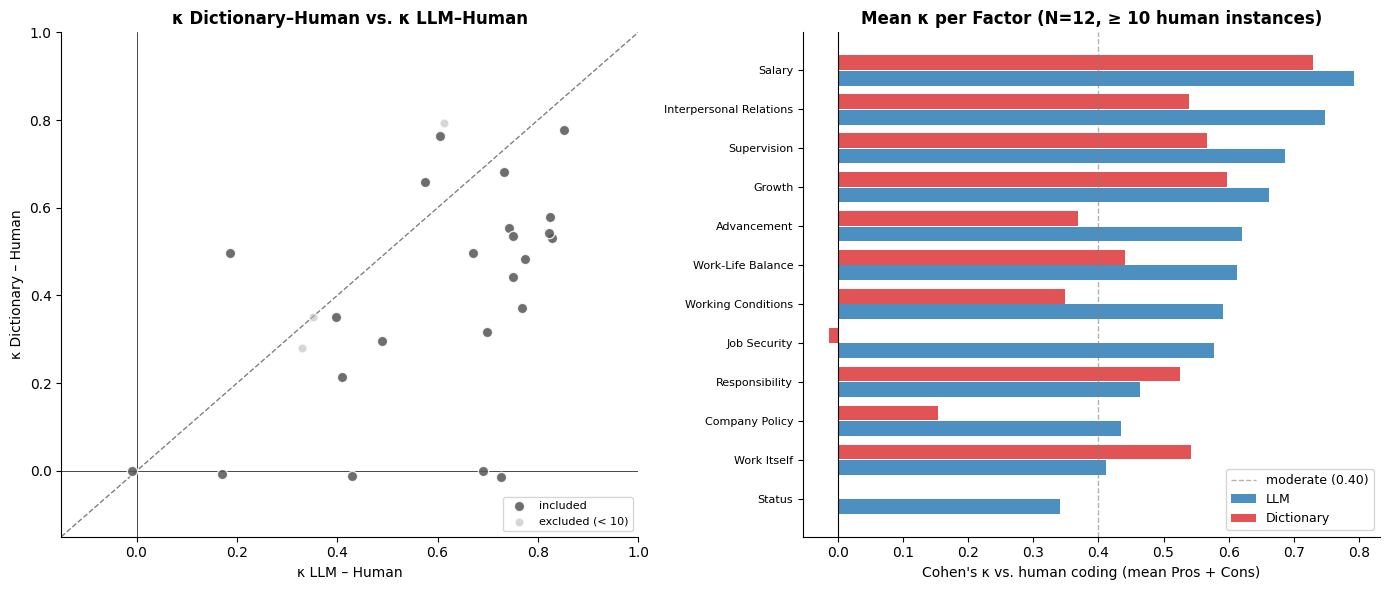

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Left: scatter κ Dict–H vs. κ LLM–H
ax = axes[0]
incl_mask = ~val["Factor"].isin(excluded)
ax.scatter(val.loc[incl_mask,  "κ LLM–Human"], val.loc[incl_mask,  "κ Dict–Human"],
           color="#555555", s=55, alpha=0.85, edgecolor="white", zorder=3, label="included")
ax.scatter(val.loc[~incl_mask, "κ LLM–Human"], val.loc[~incl_mask, "κ Dict–Human"],
           color="#bbbbbb", s=40, alpha=0.6,  edgecolor="white", zorder=2, label="excluded (< 10)")
lim = [-0.15, 1.0]
ax.plot(lim, lim, "--", color="grey", lw=1, zorder=1)
ax.axhline(0, color="black", lw=0.5)
ax.axvline(0, color="black", lw=0.5)
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("κ LLM – Human")
ax.set_ylabel("κ Dictionary – Human")
ax.set_title("κ Dictionary–Human vs. κ LLM–Human", fontweight="bold")
ax.legend(fontsize=8)
ax.spines[["top", "right"]].set_visible(False)

# Right: grouped bars,mean κ per factor (Pros + Cons averaged), included only
kappa_f = (
    val[~val["Factor"].isin(excluded)]
    .groupby(["Factor", "Type"])[["κ Dict–Human", "κ LLM–Human"]]
    .mean()
    .reset_index()
    .sort_values("κ LLM–Human")
)
ax2 = axes[1]
y = np.arange(len(kappa_f))
ax2.barh(y - 0.2, kappa_f["κ LLM–Human"],  0.38, label="LLM",        color="#2c7bb6", alpha=0.85)
ax2.barh(y + 0.2, kappa_f["κ Dict–Human"],  0.38, label="Dictionary", color="#d7191c", alpha=0.75)
ax2.axvline(0,    color="black", lw=0.8)
ax2.axvline(0.40, color="grey",  lw=1, linestyle="--", alpha=0.6, label="moderate (0.40)")
ax2.set_yticks(y)
ax2.set_yticklabels([r.Factor for _, r in kappa_f.iterrows()], fontsize=8)
ax2.set_xlabel("Cohen's κ vs. human coding (mean Pros + Cons)")
ax2.set_title(f"Mean κ per Factor (N={len(kappa_f)}, ≥ 10 human instances)", fontweight="bold")
ax2.legend(fontsize=9)
ax2.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

---
## Systematic Bias Analysis


In [29]:
rows = []
for f in FACTORS_14:
    for side in ["p", "c"]:
        y_h = base[f"{side}_{f}_h"].fillna(0)
        y_d = base[f"{side}_{f}_d"].fillna(0)
        lc  = f"{side}_{f}_llm" if f"{side}_{f}_llm" in base.columns else f"{side}_{f}"
        y_l = base[lc].fillna(0)
        rows.append({
            "Factor":     LABELS[f],
            "pct_human":  y_h.mean() * 100,
            "bias_llm":   y_l.mean() * 100 - y_h.mean() * 100,
            "bias_dict":  y_d.mean() * 100 - y_h.mean() * 100,
        })

bias_df = pd.DataFrame(rows)
fm_bias = (
    bias_df.groupby("Factor")[["pct_human", "bias_llm", "bias_dict"]]
    .mean()
    .reset_index()
    .sort_values("bias_llm")
    .reset_index(drop=True)
)

print(f"{'Factor':<26}  {'% Human':>8}  {'Bias LLM':>9}  {'Bias Dict':>10}")
print("-" * 60)
for _, r in fm_bias.iterrows():
    print(f"{r.Factor:<26}  {r.pct_human:>8.1f}  {r.bias_llm:>+9.1f}  {r.bias_dict:>+10.1f}")
print("-" * 60)
print(f"{'Mean':<26}  {'':>8}  {fm_bias.bias_llm.mean():>+9.1f}  {fm_bias.bias_dict.mean():>+10.1f}")

Factor                       % Human   Bias LLM   Bias Dict
------------------------------------------------------------
Salary                          22.9       -2.3        -3.6
Advancement                      8.0       -1.1        -5.7
Company Policy                  14.7       -0.2       -11.8
Interpersonal Relations         18.5       +0.6        -6.3
Responsibility                   3.6       +1.1        -1.9
Work-Life Balance               13.4       +1.3        -7.1
Supervision                      7.4       +1.7        -3.8
Status                           2.7       +1.9        -2.7
Recognition                      1.9       +1.9        +1.7
Working Conditions               8.4       +2.1        +1.7
Work Itself                      6.7       +2.9        -4.0
Growth                           5.9       +3.2        -2.5
Job Security                     2.9       +3.6        -2.1
Achievement                      1.3       +4.0        -1.1
---------------------------------------

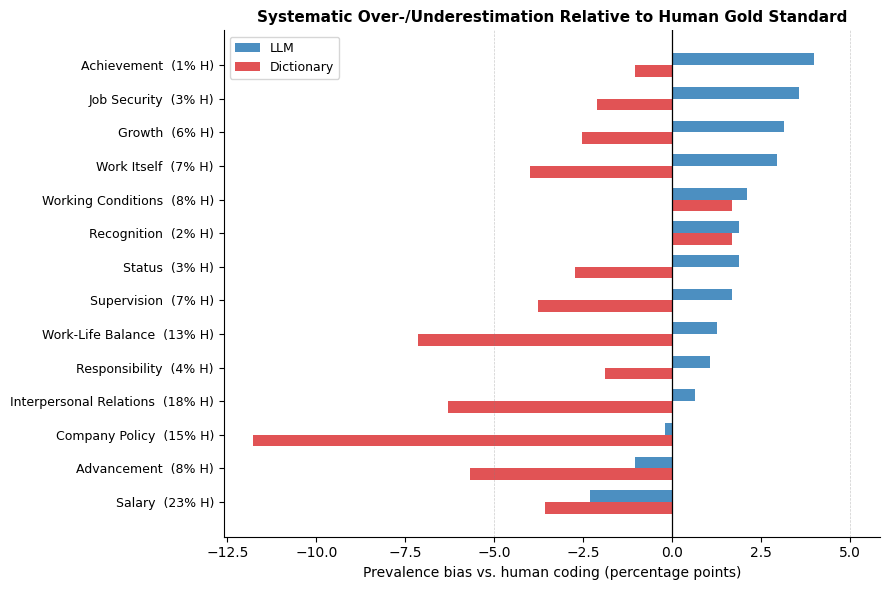

In [24]:
fig, ax = plt.subplots(figsize=(9, 6))
y = np.arange(len(fm_bias))
h = 0.35

ax.barh(y + h/2, fm_bias["bias_llm"],  h, label="LLM",        color="#2c7bb6", alpha=0.85)
ax.barh(y - h/2, fm_bias["bias_dict"], h, label="Dictionary",  color="#d7191c", alpha=0.75)

ax.axvline(0, color="black", lw=0.9)
ax.axvline(-5, color="grey", lw=0.5, ls="--", alpha=0.4)
ax.axvline( 5, color="grey", lw=0.5, ls="--", alpha=0.4)

ax.set_yticks(y)
ax.set_yticklabels(
    [f"{r.Factor}  ({r.pct_human:.0f}% H)" for _, r in fm_bias.iterrows()],
    fontsize=9
)
ax.set_xlabel("Prevalence bias vs. human coding (percentage points)", fontsize=10)
ax.set_title("Systematic Over-/Underestimation Relative to Human Gold Standard",
             fontweight="bold", fontsize=11)
ax.legend(fontsize=9)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

---
## Cross-Platform Comparison: Kununu vs. Glassdoor


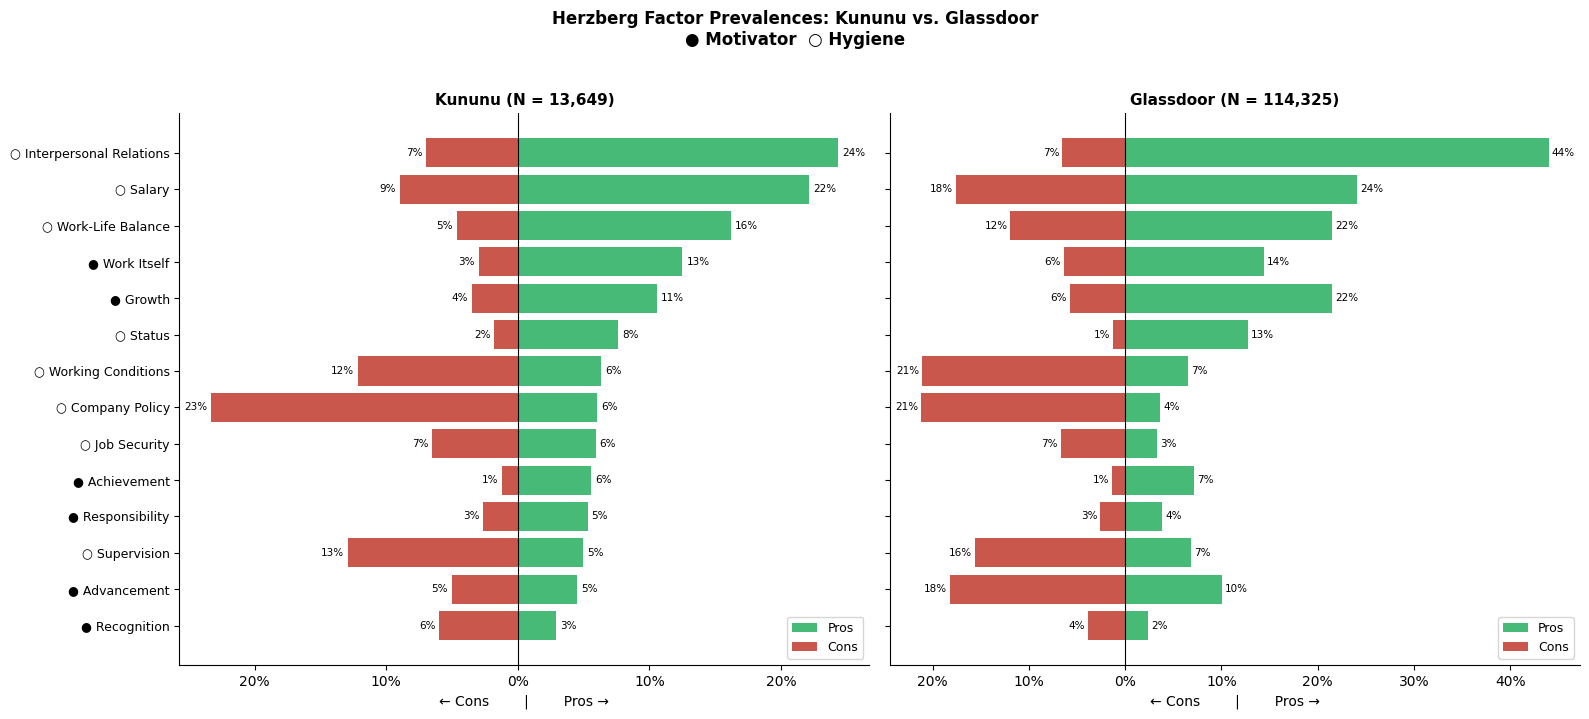

In [28]:
with sqlite3.connect(DB_PATH) as conn:
    kununu    = pd.read_sql("SELECT * FROM llm_proscons_kununu", conn)
    glassdoor = pd.read_sql("SELECT * FROM classifications_llm", conn)

def factor_prevalences(df):
    rows = []
    for f in FACTORS_14:
        rows.append({
            "Factor": LABELS[f],
            "Type":   "Hygiene" if f in HYGIENE else "Motivator",
            "pct_pros": df[f"p_{f}"].fillna(0).mean() * 100,
            "pct_cons": df[f"c_{f}"].fillna(0).mean() * 100,
        })
    return pd.DataFrame(rows)

k = factor_prevalences(kununu)
g = factor_prevalences(glassdoor)

# Sort by Kununu pros prevalence 
order = k.sort_values("pct_pros")["Factor"].tolist()
k = k.set_index("Factor").loc[order].reset_index()
g = g.set_index("Factor").loc[order].reset_index()

fig, axes = plt.subplots(1, 2, figsize=(16, 7), sharey=True)

for ax, df, title in zip(
    axes,
    [k, g],
    [f"Kununu (N = {len(kununu):,})", f"Glassdoor (N = {len(glassdoor):,})"],
):
    y = np.arange(len(df))
    ax.barh(y,  df["pct_pros"], color="#27ae60", alpha=0.85, label="Pros")
    ax.barh(y, -df["pct_cons"], color="#c0392b", alpha=0.85, label="Cons")
    ax.axvline(0, color="black", lw=0.8)

    for yi, (_, r) in zip(y, df.iterrows()):
        ax.text( r["pct_pros"] + 0.3, yi, f"{r['pct_pros']:.0f}%", va="center", fontsize=7.5)
        ax.text(-r["pct_cons"] - 0.3, yi, f"{r['pct_cons']:.0f}%", va="center", ha="right", fontsize=7.5)

    ax.set_yticks(y)
    ax.set_yticklabels(
        [f"{'● ' if r.Type == 'Motivator' else '○ '}{r.Factor}" for _, r in df.iterrows()],
        fontsize=9
    )
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{abs(v):.0f}%"))
    ax.set_xlabel("← Cons        |        Pros →")
    ax.set_title(title, fontweight="bold", fontsize=11)
    ax.legend(loc="lower right", fontsize=9)
    ax.spines[["top", "right"]].set_visible(False)

plt.suptitle("Herzberg Factor Prevalences: Kununu vs. Glassdoor\n● Motivator  ○ Hygiene",
             fontweight="bold", fontsize=12, y=1.02)
plt.tight_layout()
plt.show()

In [27]:
from scipy.stats import spearmanr

rows = []
for f in FACTORS_14:
    for side, label in [("p", "Pros"), ("c", "Cons")]:
        rows.append({
            "Factor": LABELS[f],
            "Field":  label,
            "pct_kununu":    kununu[f"{side}_{f}"].fillna(0).mean() * 100,
            "pct_glassdoor": glassdoor[f"{side}_{f}"].fillna(0).mean() * 100,
        })
cross = pd.DataFrame(rows)

rho_all,  p_all  = spearmanr(cross["pct_kununu"], cross["pct_glassdoor"])
rho_pros, p_pros = spearmanr(cross[cross.Field=="Pros"]["pct_kununu"],
                             cross[cross.Field=="Pros"]["pct_glassdoor"])
rho_cons, p_cons = spearmanr(cross[cross.Field=="Cons"]["pct_kununu"],
                             cross[cross.Field=="Cons"]["pct_glassdoor"])

print("Spearman rank correlation of factor prevalences: Kununu vs. Glassdoor")
print("=" * 60)
print(f"  All 28 (14 factors × Pros/Cons):  ρ = {rho_all:.3f}  (p = {p_all:.4f})")
print(f"  Pros only (N = 14):               ρ = {rho_pros:.3f}  (p = {p_pros:.4f})")
print(f"  Cons only (N = 14):               ρ = {rho_cons:.3f}  (p = {p_cons:.4f})")

Spearman rank correlation of factor prevalences: Kununu vs. Glassdoor
  All 28 (14 factors × Pros/Cons):  ρ = 0.804  (p = 0.0000)
  Pros only (N = 14):               ρ = 0.798  (p = 0.0006)
  Cons only (N = 14):               ρ = 0.833  (p = 0.0002)


### Factor Mentions per Review

(Additional descriptive information)

 Platform Field  Mean factors  Median factors   SD
   Kununu  Pros          1.35            1.00 1.36
   Kununu  Cons          0.99            1.00 1.41
Glassdoor  Pros          1.82            2.00 1.26
Glassdoor  Cons          1.40            1.00 1.16


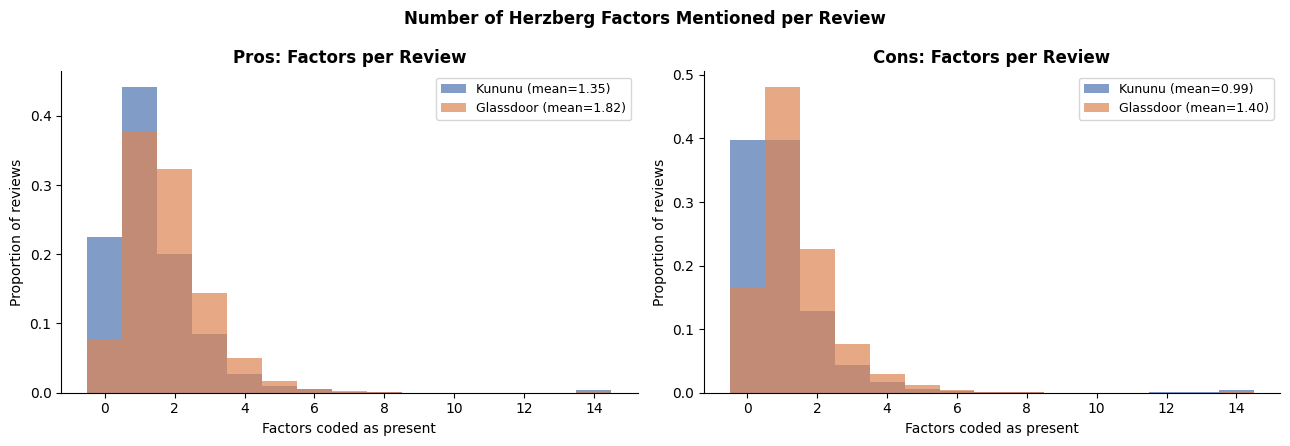


Glassdoor Pros: +0.47 factors/review more than Kununu
Glassdoor Cons: +0.41 factors/review more than Kununu


In [ ]:
P_COLS = [f"p_{f}" for f in FACTORS_14]
C_COLS = [f"c_{f}" for f in FACTORS_14]

k_pros = kununu[P_COLS].fillna(0).sum(axis=1)
k_cons = kununu[C_COLS].fillna(0).sum(axis=1)
g_pros = glassdoor[P_COLS].fillna(0).sum(axis=1)
g_cons = glassdoor[C_COLS].fillna(0).sum(axis=1)

summary = pd.DataFrame({
    "Platform":       ["Kununu", "Kununu", "Glassdoor", "Glassdoor"],
    "Field":          ["Pros",   "Cons",   "Pros",      "Cons"],
    "Mean factors":   [k_pros.mean(), k_cons.mean(), g_pros.mean(), g_cons.mean()],
    "Median factors": [k_pros.median(), k_cons.median(), g_pros.median(), g_cons.median()],
    "SD":             [k_pros.std(),  k_cons.std(),  g_pros.std(),  g_cons.std()],
})
print(summary.to_string(index=False, float_format=lambda x: f"{x:.2f}"))

# Plot: distribution of factor count per review 
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=False)

for ax, (k_s, g_s, field) in zip(axes, [(k_pros, g_pros, "Pros"), (k_cons, g_cons, "Cons")]):
    bins = np.arange(-0.5, 15.5, 1)
    ax.hist(k_s, bins=bins, density=True, alpha=0.7, color="#4C72B0",
            label=f"Kununu (mean={k_s.mean():.2f})")
    ax.hist(g_s, bins=bins, density=True, alpha=0.7, color="#DD8452",
            label=f"Glassdoor (mean={g_s.mean():.2f})")
    ax.set_xlabel("Factors coded as present")
    ax.set_ylabel("Proportion of reviews")
    ax.set_title(f"{field}: Factors per Review", fontweight="bold")
    ax.legend(fontsize=9)
    ax.spines[["top", "right"]].set_visible(False)

plt.suptitle("Number of Herzberg Factors Mentioned per Review",
             fontweight="bold", fontsize=12)
plt.tight_layout()
plt.show()

print(f"\nGlassdoor Pros: +{g_pros.mean() - k_pros.mean():.2f} factors/review more than Kununu")
print(f"Glassdoor Cons: +{g_cons.mean() - k_cons.mean():.2f} factors/review more than Kununu")